# 04 – Model comparison (RF vs XGBoost vs ANN vs Hybrid RF + ANN)
Loads the saved Random Forest and XGBoost, trains the ANN, builds the hybrid, then evaluates **all models on the same held-out test set** and writes `results/metrics.json`, `results/predictions.csv` and `results/feature_importance.csv` for the dashboard.

In [1]:
import os, warnings, json, joblib; warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"]="3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from xgboost import XGBRegressor
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from common import *
sns.set_theme(style="whitegrid"); tf.random.set_seed(SEED); np.random.seed(SEED)
pre = joblib.load(MODELS/"preprocessor.pkl")
rf  = joblib.load(MODELS/"random_forest.pkl")
xgb = XGBRegressor(); xgb.load_model(MODELS/"xgboost.json")
(Xtr,ytr),(Xva,yva),(Xte,yte) = load_split("train"),load_split("val"),load_split("test")
Atr,Ava,Ate = pre.transform(Xtr),pre.transform(Xva),pre.transform(Xte)

I0000 00:00:1795329098.062710     681 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795329115.929355     681 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## ANN (Keras) – same encoded features; early stopping on the validation set

epochs run: 32


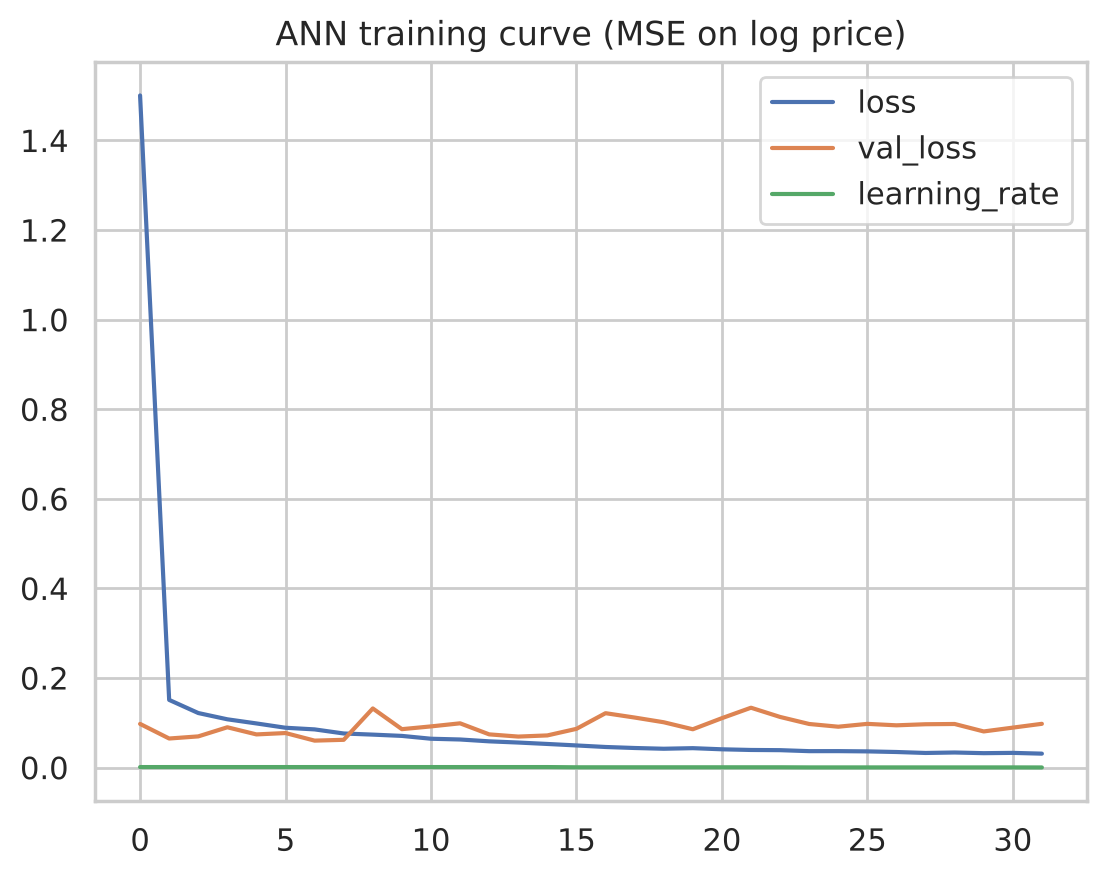

In [2]:
ann = tf.keras.Sequential([tf.keras.layers.Input((Atr.shape[1],)),
    tf.keras.layers.Dense(256,activation="relu"), tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128,activation="relu"), tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(64,activation="relu"), tf.keras.layers.Dense(1)])
ann.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
hist = ann.fit(Atr, ytr.values, validation_data=(Ava,yva.values), epochs=300, batch_size=64, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=25,restore_best_weights=True), tf.keras.callbacks.ReduceLROnPlateau(patience=8,factor=0.5)])
print("epochs run:", len(hist.history["loss"]))
pd.DataFrame(hist.history).plot(title="ANN training curve (MSE on log price)"); plt.show()
ann.save(MODELS/"ann.keras"); pd.DataFrame(hist.history).to_csv(RESULTS/"ann_history.csv", index=False)

## Hybrid RF + ANN – weighted average, weight chosen on the validation set only

In [3]:
pv = {"Random Forest":rf.predict(Ava), "XGBoost":xgb.predict(Ava), "ANN":ann.predict(Ava,verbose=0).ravel()}
pt = {"Random Forest":rf.predict(Ate), "XGBoost":xgb.predict(Ate), "ANN":ann.predict(Ate,verbose=0).ravel()}
ws = np.linspace(0,1,101)
w_rf = float(min(ws, key=lambda w: mean_squared_error(yva, w*pv["Random Forest"]+(1-w)*pv["ANN"])))
print(f"Hybrid = {w_rf:.2f} x RF + {1-w_rf:.2f} x ANN")
for d in (pv,pt): d["Hybrid RF+ANN"] = w_rf*d["Random Forest"] + (1-w_rf)*d["ANN"]

Hybrid = 0.76 x RF + 0.24 x ANN


## Final test-set metrics

,MAE,MSE,RMSE,R2
Random Forest,6.394000,578.199000,24.046000,0.761000
XGBoost,5.919000,527.394000,22.965000,0.782000
ANN,10.389000,733.518000,27.084000,0.697000
Hybrid RF+ANN,6.789000,590.220000,24.294000,0.756000


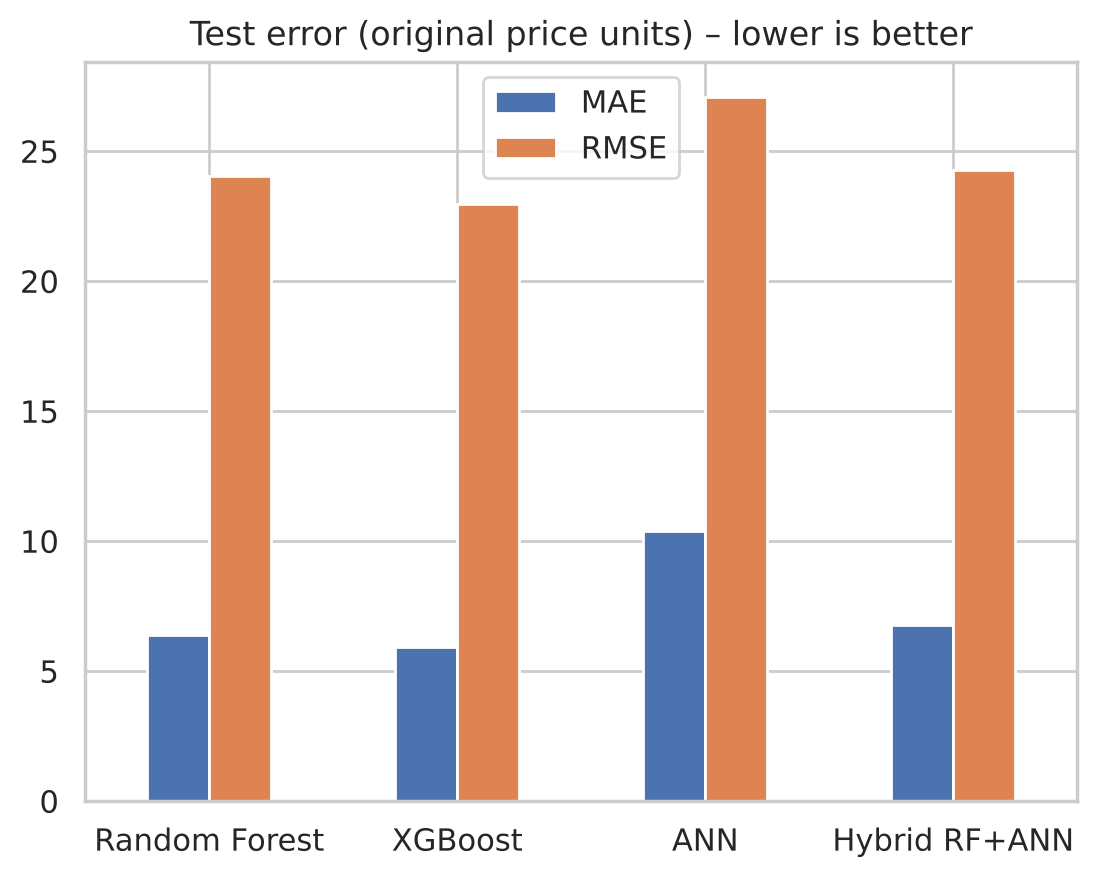

In [4]:
res = pd.DataFrame({k:evaluate(yte,v) for k,v in pt.items()}).T
display(res.round(3).style.highlight_min(subset=["MAE","MSE","RMSE"],color="#cfe8cf").highlight_max(subset=["R2"],color="#cfe8cf"))
res[["MAE","RMSE"]].plot.bar(rot=0,title="Test error (original price units) – lower is better"); plt.show()

### Is RF vs XGBoost a real difference? Bootstrap 95% CI on the test set

In [5]:
rng = np.random.default_rng(SEED); t = np.expm1(yte.values)
p_rf, p_xgb = np.expm1(pt["Random Forest"]), np.expm1(pt["XGBoost"]); dm, dr = [], []
for _ in range(2000):
    i = rng.integers(0,len(t),len(t))
    dm.append(mean_absolute_error(t[i],p_rf[i]) - mean_absolute_error(t[i],p_xgb[i]))
    dr.append(mean_squared_error(t[i],p_rf[i])**.5 - mean_squared_error(t[i],p_xgb[i])**.5)
boot = {}
for n,d in [("MAE",dm),("RMSE",dr)]:
    lo,hi = np.percentile(d,[2.5,97.5]); boot[n] = {"mean_diff_RF_minus_XGB":float(np.mean(d)),"ci95":[float(lo),float(hi)]}
    print(f"RF − XGB {n}: mean {np.mean(d):+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}] ->", "significant" if lo>0 or hi<0 else "CI includes 0: no clear winner")

RF − XGB MAE: mean +0.481, 95% CI [+0.191, +0.785] -> significant
RF − XGB RMSE: mean +1.293, 95% CI [+0.081, +3.106] -> significant


## Actual vs predicted and residuals

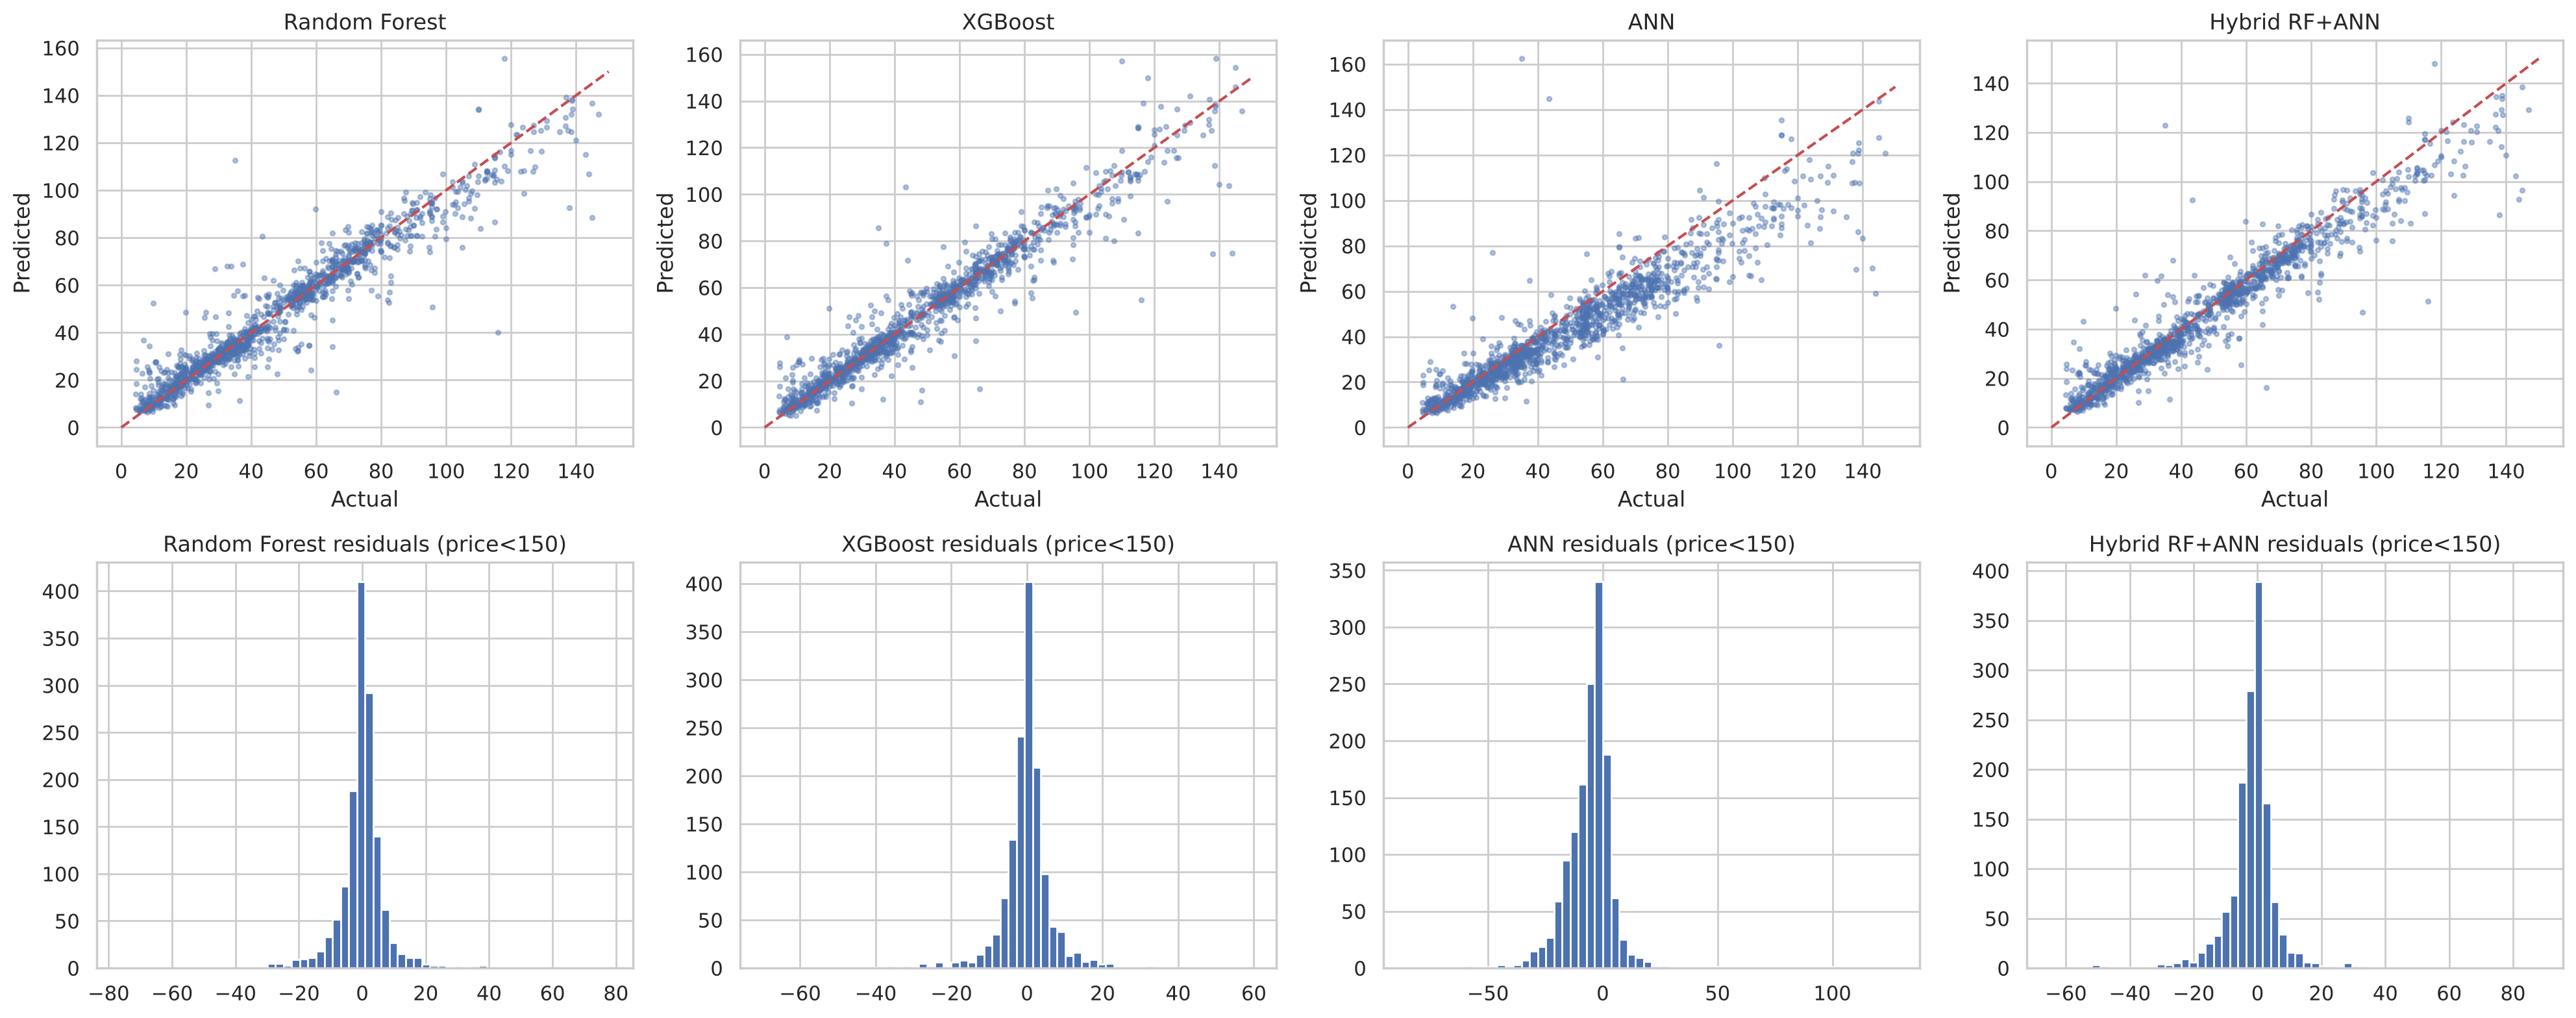

In [6]:
fig,ax = plt.subplots(2,4,figsize=(20,8)); a = np.expm1(yte.values)
for j,(k,v) in enumerate(pt.items()):
    p = np.expm1(v); m = a<150
    ax[0,j].scatter(a[m],p[m],s=6,alpha=.4); ax[0,j].plot([0,150],[0,150],"r--"); ax[0,j].set(title=k,xlabel="Actual",ylabel="Predicted")
    ax[1,j].hist((p-a)[m],bins=60); ax[1,j].set(title=f"{k} residuals (price<150)")
plt.tight_layout(); plt.show()

## Feature importance (RF vs XGBoost)

,Random Forest,XGBoost
Gear,0.303,0.177
YOM,0.169,0.014
Mileage,0.156,0.024
Brand,0.105,0.314
Model,0.056,0.356
Engine,0.053,0.007
PM,0.049,0.027
PW,0.034,0.008
Town,0.028,0.047
PS,0.023,0.004


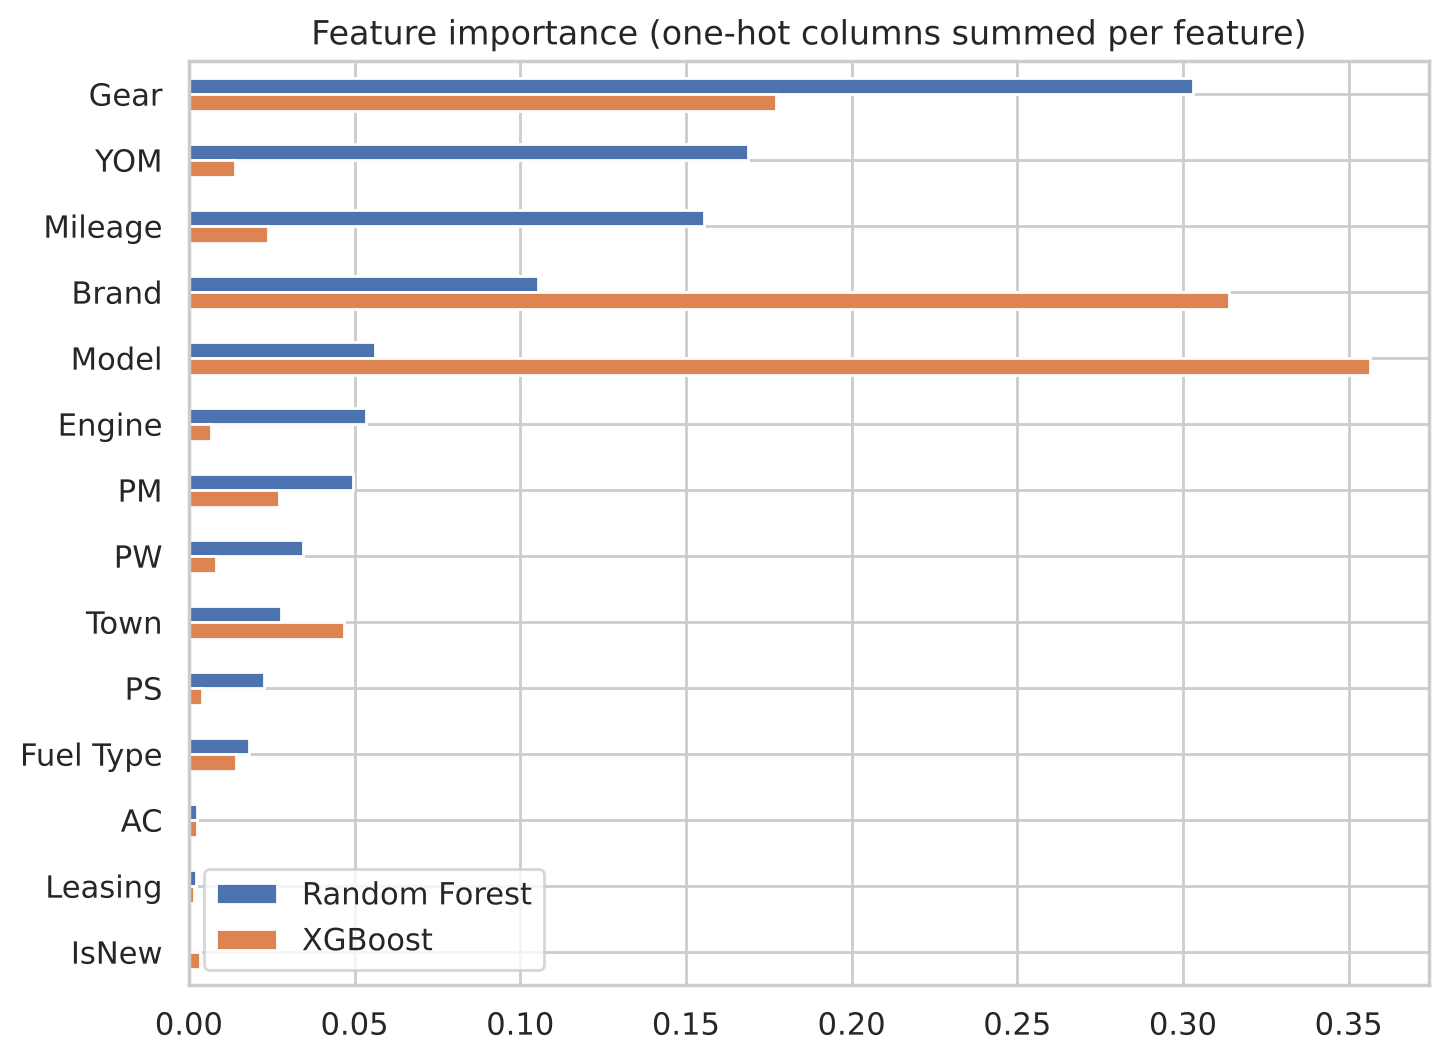

In [7]:
fn = pre.get_feature_names_out()
def agg(imp):
    out = {}
    for n,v in zip(fn,imp):
        b = n.split("__",1)[1]
        for c in CAT:
            if b.startswith(c+"_"): b = c; break
        out[b] = out.get(b,0)+v
    return pd.Series(out)
fi = pd.DataFrame({"Random Forest":agg(rf.feature_importances_),"XGBoost":agg(xgb.feature_importances_)}).sort_values("Random Forest",ascending=False)
display(fi.round(3)); fi.plot.barh(figsize=(8,6)).invert_yaxis(); plt.title("Feature importance (one-hot columns summed per feature)"); plt.show()

## Save results for the dashboard

In [8]:
json.dump({"test":res.to_dict("index"),"hybrid_rf_weight":w_rf,"bootstrap_rf_vs_xgb":boot,
           "n_train":len(Xtr),"n_val":len(Xva),"n_test":len(Xte),"n_features":int(Atr.shape[1])}, open(RESULTS/"metrics.json","w"), indent=1)
pd.DataFrame({"actual":a, **{k:np.expm1(v) for k,v in pt.items()}}).to_csv(RESULTS/"predictions.csv", index=False)
fi.reset_index().rename(columns={"index":"feature"}).to_csv(RESULTS/"feature_importance.csv", index=False)
print("saved:", sorted(p.name for p in RESULTS.iterdir()))

saved: ['ann_history.csv', 'feature_importance.csv', 'metrics.json', 'predictions.csv', 'rf_results.json', 'xgb_results.json']


## Conclusions
Write these in your own words after reading the results above:
- Which of RF / XGBoost had lower test error, and does the bootstrap CI show the gap is meaningful?
- How much did tuning help each model (see notebooks 02 and 03)?
- Did the hybrid improve on both of its components, or only on the ANN?
- Which features matter most, and do both models agree?
- Limitations: mileage is almost determined by year; prices are asking prices; errors are larger for expensive vehicles.